# 🧠 Proje 1 · Bölüm 1 — Bir MR görüntüsü bilgisayar için nedir?
**Seviye: Başlangıç** · Tahmini süre: 20 dk

Bu proje boyunca beyin MR kesitlerinde **tümör var / yok** ayrımı yapan bir yapay zeka modeli geliştireceğiz ve bunu telefonda çalışan bir uygulamaya dönüştüreceğiz.

| Bölüm | Konu | Seviye |
|---|---|---|
| **1.1 (bu dosya)** | Görüntü = sayı matrisi, veri setini tanıma, ön işleme, veri kalitesi | Başlangıç |
| 1.2 | Klasik makine öğrenmesi: "özellikleri biz tasarlarız" | Orta |
| 1.3 | Derin öğrenme (CNN): "özellikleri model öğrenir" | İleri |
| 1.4 | Açıklanabilirlik (model nereye baktı?) ve mobil uygulamaya aktarma | İleri |

> ⚠️ **Eğitim amaçlıdır.** Bu veri seti küçüktür (253 görüntü) ve klinik karar için kullanılamaz.

**Veri seti:** *Brain MRI Images for Brain Tumor Detection* (N. Chakrabarty, Kaggle). 155 tümörlü, 98 tümörsüz aksiyel MR kesiti; farklı sekanslar (T1, T2, FLAIR) ve farklı kaynaklardan derlenmiştir.

In [1]:
# Google Colab'da çalışıyorsanız: proje klasörünü (zip) yükleyip açın
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 01_Beyin_MR_Tumor.zip dosyasını seçin")
    yuklenen = files.upload()
    !unzip -q -o 01_Beyin_MR_Tumor.zip
    %cd 01_Beyin_MR_Tumor
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/01_Beyin_MR_Tumor


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
plt.rcParams["figure.dpi"] = 110

VERI = Path("veri")
dosyalar = {sinif: sorted((VERI / sinif).iterdir()) for sinif in ["tumor_var", "tumor_yok"]}
for sinif, liste in dosyalar.items():
    print(f"{sinif:10s}: {len(liste)} görüntü")

tumor_var : 155 görüntü
tumor_yok : 98 görüntü


## 1. Bilgisayar bir görüntüyü nasıl "görür"?
Bir radyolog görüntüye baktığında anatomiyi görür. Bilgisayar ise yalnızca **sayılardan oluşan bir tablo** görür: her hücre (piksel) 0 (siyah) ile 255 (beyaz) arasında bir parlaklık değeridir.

Dosya: Y1.jpg
Boyut (satır x sütun): (218, 180) → toplam 39240 piksel


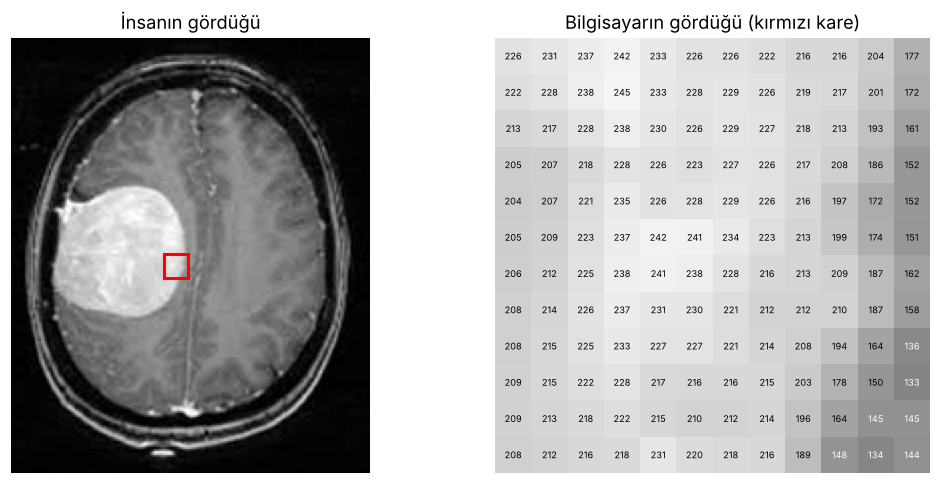

In [3]:
ornek = dosyalar["tumor_var"][0]
img = np.asarray(Image.open(ornek).convert("L"))      # "L" = gri tonlama
print("Dosya:", ornek.name)
print("Boyut (satır x sütun):", img.shape, "→ toplam", img.size, "piksel")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("İnsanın gördüğü")
y, x = 108, 76                                         # tümörün kenarından küçük bir pencere
ax[0].add_patch(plt.Rectangle((x, y), 12, 12, fill=False, ec="red", lw=2))
parca = img[y:y+12, x:x+12]
ax[1].imshow(parca, cmap="gray", vmin=0, vmax=255)
for i in range(12):
    for j in range(12):
        ax[1].text(j, i, parca[i, j], ha="center", va="center", fontsize=6,
                   color="white" if parca[i, j] < 150 else "black")
ax[1].set_title("Bilgisayarın gördüğü (kırmızı kare)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Veri setine genel bakış
Gerçek hayatta veriler **dağınıktır**: farklı cihazlar, farklı boyutlar, farklı sekanslar. Önce neyle çalıştığımızı görelim.

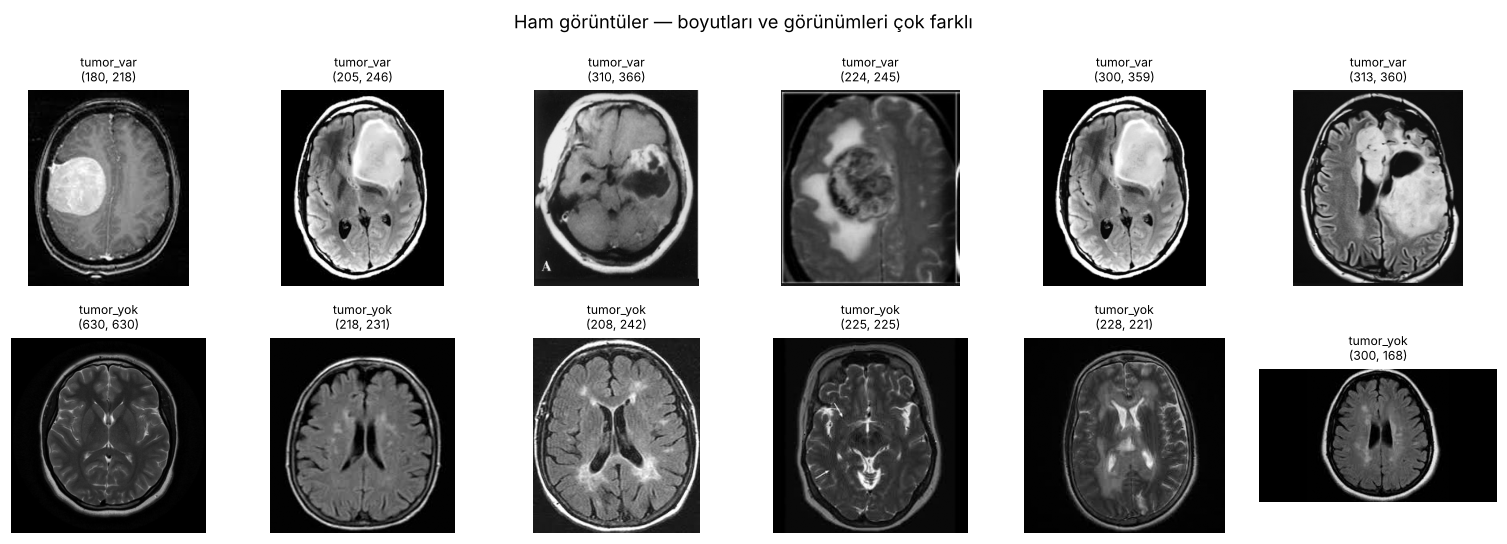

En küçük: [150 168]  En büyük: [1920 1427]  Medyan: [278. 331.]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r, sinif in enumerate(["tumor_var", "tumor_yok"]):
    for c in range(6):
        f = dosyalar[sinif][c * 7]
        axes[r, c].imshow(Image.open(f).convert("L"), cmap="gray")
        axes[r, c].set_title(f"{sinif}\n{Image.open(f).size}", fontsize=8)
        axes[r, c].axis("off")
plt.suptitle("Ham görüntüler — boyutları ve görünümleri çok farklı"); plt.tight_layout(); plt.show()

boyutlar = np.array([Image.open(f).size for l in dosyalar.values() for f in l])
print("En küçük:", boyutlar.min(0), " En büyük:", boyutlar.max(0), " Medyan:", np.median(boyutlar, 0))

## 3. Ön işleme: modelin işini kolaylaştırmak
Modelin tümöre odaklanmasını isteriz; siyah arka plana, yazılara, çerçevelere değil. Bu yüzden her görüntüye **aynı adımları** uygularız. Bu adımlar `beyin_on_isleme.py` dosyasındadır ve **mobil uygulamada da birebir aynısı** çalışır.

1. **Gri tonlama** → tek kanal
2. **Bulanıklaştırma** → gürültüyü azaltma
3. **Eşikleme** → parlak bölge (kafa) = 1, karanlık (arka plan) = 0
4. **En büyük bağlı bölge** → kafa dışındaki küçük lekeleri (yazı, işaret) atma
5. **Kırpma ve 128×128'e küçültme** → herkes aynı boyutta

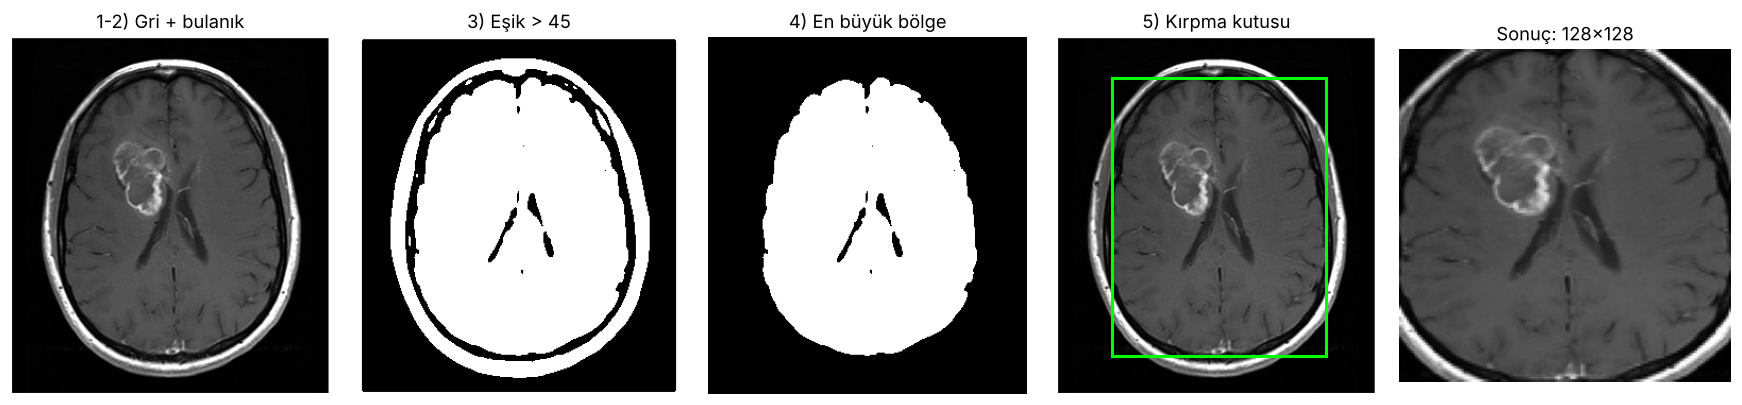

In [5]:
from beyin_on_isleme import gri_oku, kutu_bulaniklastir, beyin_maskesi, beyin_kirp, alan_boyutla, ESIK

f = dosyalar["tumor_var"][3]
gri = gri_oku(f)
bulanik = kutu_bulaniklastir(kutu_bulaniklastir(gri))
esikli = bulanik > ESIK
maske = beyin_maskesi(gri)
kirp, (y0, y1, x0, x1) = beyin_kirp(gri)
son = alan_boyutla(kirp)

adimlar = [(gri, "1-2) Gri + bulanık"), (esikli, f"3) Eşik > {ESIK}"), (maske, "4) En büyük bölge"),
           (gri, "5) Kırpma kutusu"), (son, "Sonuç: 128×128")]
fig, ax = plt.subplots(1, 5, figsize=(16, 3.6))
for a, (im, t) in zip(ax, adimlar):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
ax[3].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=2))
plt.tight_layout(); plt.show()

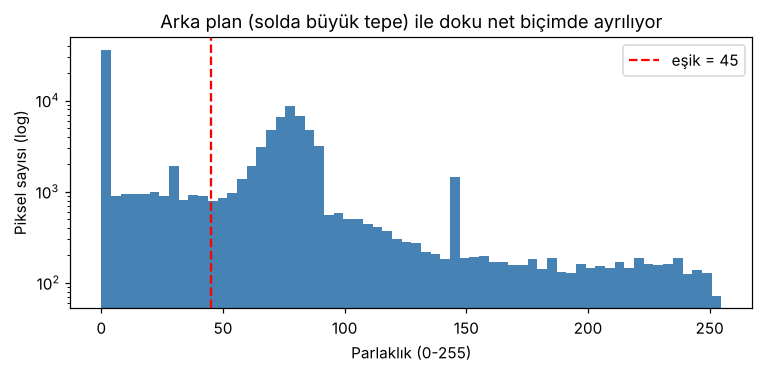

In [6]:
# Parlaklık dağılımı (histogram): eşik değerini neden 45 seçtik?
plt.figure(figsize=(8, 3.2))
plt.hist(bulanik.ravel(), bins=64, color="steelblue")
plt.axvline(ESIK, color="red", ls="--", label=f"eşik = {ESIK}")
plt.yscale("log"); plt.xlabel("Parlaklık (0-255)"); plt.ylabel("Piksel sayısı (log)")
plt.title("Arka plan (solda büyük tepe) ile doku net biçimde ayrılıyor"); plt.legend(); plt.show()

## 4. Tüm veri setini işleyelim

X: (253, 128, 128)  y: (253,)  Tümör oranı: 61.3%


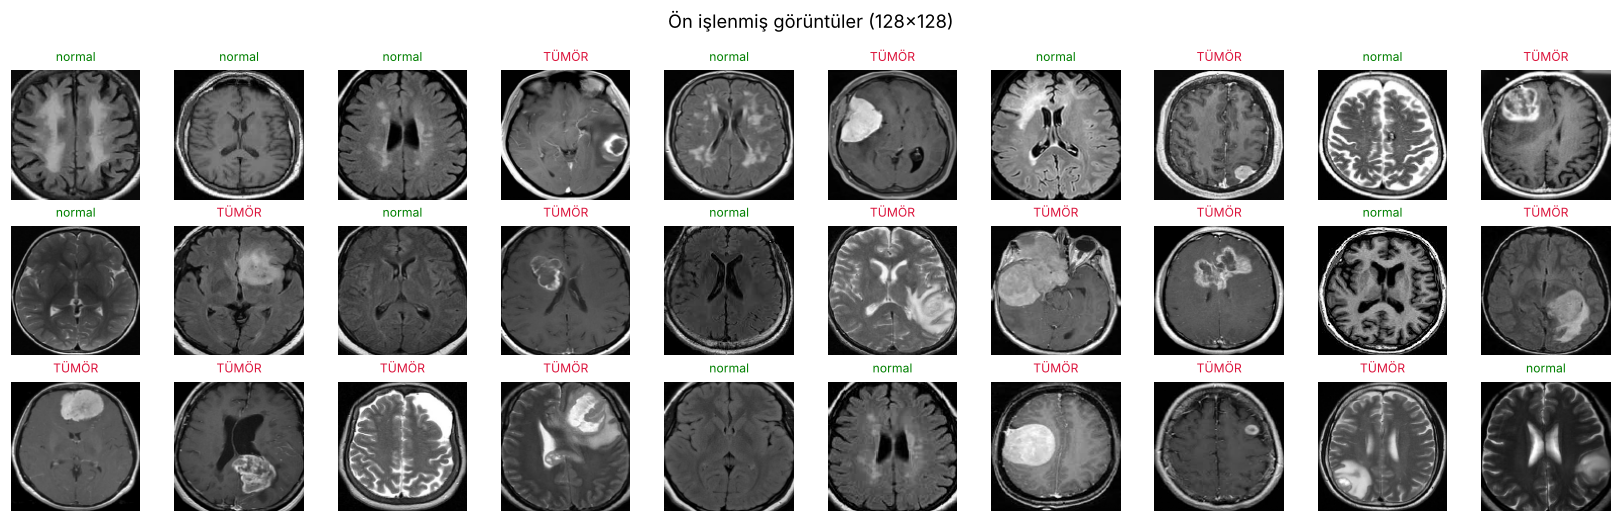

In [7]:
from beyin_on_isleme import on_isle

yollar, etiketler = [], []
for etiket, sinif in [(1, "tumor_var"), (0, "tumor_yok")]:
    for f in dosyalar[sinif]:
        yollar.append(f); etiketler.append(etiket)
X = np.stack([on_isle(f) for f in yollar]).astype(np.float32)
y = np.array(etiketler)
print("X:", X.shape, " y:", y.shape, " Tümör oranı: %.1f%%" % (100 * y.mean()))

fig, axes = plt.subplots(3, 10, figsize=(15, 4.8))
idx = np.random.default_rng(0).choice(len(X), 30, replace=False)
for a, i in zip(axes.ravel(), idx):
    a.imshow(X[i], cmap="gray"); a.set_title("TÜMÖR" if y[i] else "normal", fontsize=8,
                                             color="crimson" if y[i] else "green"); a.axis("off")
plt.suptitle("Ön işlenmiş görüntüler (128×128)"); plt.tight_layout(); plt.show()

## 5. Veri kalitesi kontrolü — işbirliğinde en çok atlanan adım 🔎
Yapay zeka projelerinin çoğu **algoritma** yüzünden değil **veri** yüzünden başarısız olur. İki klasik sorun:

* **Kopya görüntüler:** Aynı görüntü hem eğitimde hem testte varsa model "ezberler" ve başarı sahte biçimde yüksek görünür (*veri sızıntısı*).
* **Kısayol öğrenme (shortcut learning):** Sınıflar farklı kaynaklardan geliyorsa, model hastalığı değil *kaynağı* tanımayı öğrenebilir (ör. yazı tipi, çerçeve, sekans türü).

Basit bir "görüntü parmak izi" (hash) ile birbirine çok benzeyen görüntüleri bulalım:

Neredeyse aynı görüntü çifti sayısı: 58


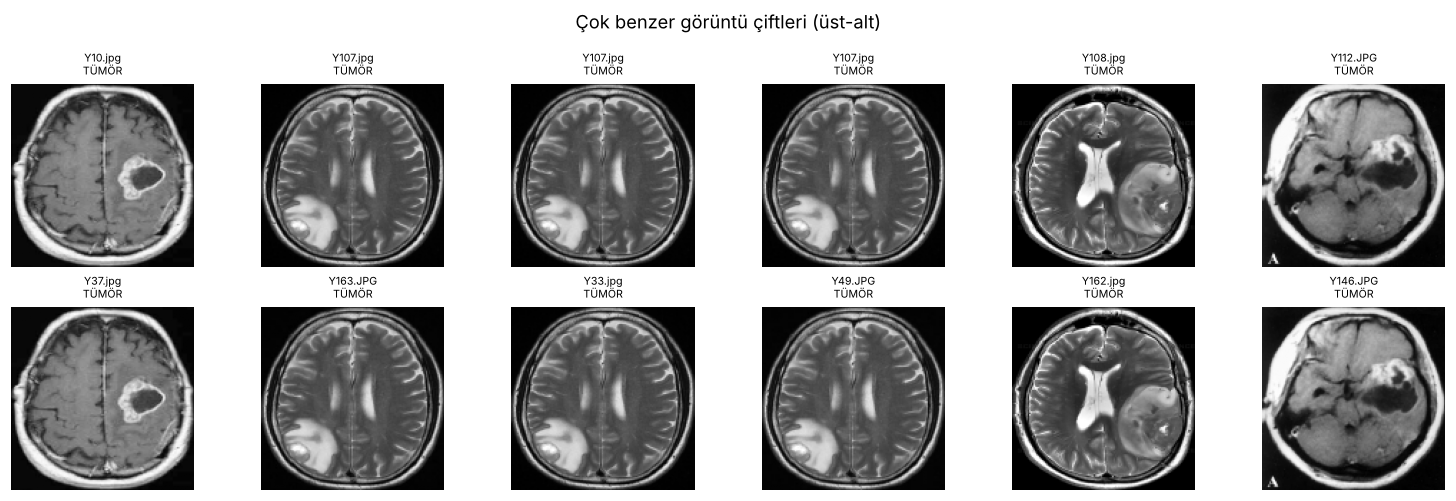

In [8]:
def parmak_izi(x, n=16):
    k = alan_boyutla(x * 255, n)
    return (k > np.median(k)).ravel()        # 256 bitlik "ortalama hash"

izler = np.stack([parmak_izi(x) for x in X])
fark = (izler[:, None, :] != izler[None, :, :]).sum(-1)    # Hamming mesafesi
ciftler = [(i, j) for i in range(len(X)) for j in range(i + 1, len(X)) if fark[i, j] <= 12]
print(f"Neredeyse aynı görüntü çifti sayısı: {len(ciftler)}")

if ciftler:
    n = min(6, len(ciftler))
    fig, axes = plt.subplots(2, n, figsize=(2.3 * n, 4.6), squeeze=False)
    for k, (i, j) in enumerate(ciftler[:n]):
        for r, t in enumerate([i, j]):
            axes[r, k].imshow(X[t], cmap="gray"); axes[r, k].axis("off")
            axes[r, k].set_title(f"{yollar[t].name}\n{'TÜMÖR' if y[t] else 'normal'}", fontsize=7)
    plt.suptitle("Çok benzer görüntü çiftleri (üst-alt)"); plt.tight_layout(); plt.show()

**Çözüm:** Benzer görüntüleri bir **grup** olarak işaretleyip aynı grubu hep aynı tarafa (ya eğitim ya test) koyacağız. Böylece test seti gerçekten "hiç görülmemiş" görüntülerden oluşur.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# Benzer çiftleri birleştirerek grup numarası ver (birleşim-bul)
grup = np.arange(len(X))
def kok(i):
    while grup[i] != i:
        grup[i] = grup[grup[i]]; i = grup[i]
    return i
for i, j in ciftler:
    grup[kok(i)] = kok(j)
gruplar = np.array([kok(i) for i in range(len(X))])
print("Görüntü:", len(X), " Bağımsız grup:", len(np.unique(gruplar)))

# Sabit bir test seti ayıralım (%20). Tüm bölümler aynı test setini kullanacak.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
egitim_idx, test_idx = next(sgkf.split(X, y, gruplar))
bolum = np.array(["egitim"] * len(X), dtype=object); bolum[test_idx] = "test"
for b in ["egitim", "test"]:
    m = bolum == b
    print(f"{b:7s}: {m.sum():3d} görüntü | tümör oranı %{100 * y[m].mean():.0f}")

Görüntü: 253  Bağımsız grup: 210
egitim : 202 görüntü | tümör oranı %61
test   :  51 görüntü | tümör oranı %61


In [10]:
Path("islenmis").mkdir(exist_ok=True)
np.savez_compressed("islenmis/veri_128.npz", X=X, y=y, grup=gruplar, bolum=bolum.astype(str),
                    dosya=np.array([str(p) for p in yollar]))
print("Kaydedildi → islenmis/veri_128.npz")

Kaydedildi → islenmis/veri_128.npz


## ✅ Bu bölümde öğrendiklerimiz
* Görüntü, bilgisayar için bir **sayı matrisidir**.
* **Ön işleme** (kırpma, boyutlandırma) modelin doğru yere odaklanmasını sağlar ve **mobil uygulamada da aynen tekrarlanmalıdır**.
* **Veri kalitesi** (kopyalar, kaynak farklılıkları) sonucu algoritmadan daha çok etkileyebilir. Bir hekim olarak işbirliğinde soracağınız ilk soru: *"Test seti nasıl ayrıldı? Aynı hasta hem eğitimde hem testte var mı?"*

➡️ Sonraki bölüm: **1.2 Klasik makine öğrenmesi**